<a href="https://colab.research.google.com/github/saraxfl/Notebook/blob/main/Collab3_Bloque2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 3. Ozono horario en UAM Iztapalapa

Analice si el 03 de la estación UIZ se comporto como una serie estacionaria al retirar sus ciclos diarios y mensuales.

In [1]:
from pathlib import Path
from urllib.request import urlretrieve

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.linear_model import LinearRegression
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import adfuller, kpss

archivo = Path("contaminantes_2026.csv")
url = "https://aire.cdmx.gob.mx/descargas/Opendata/anuales_horarios/contaminantes_2026.csv"
if not archivo.exists():
    try:
        urlretrieve(url, archivo)
    except OSError as error:
        raise RuntimeError("Sube contaminantes_2026.csv al panel Archivos de Colab y vuelve a ejecutar.") from error

columnas = {"date", "id_station", "id_parameter", "valor"}
mediciones = pd.read_csv(archivo, skiprows=9, usecols=lambda col: col in columnas)
ozono = mediciones.loc[
    mediciones["id_station"].eq("UIZ") & mediciones["id_parameter"].eq("O3"), ["date", "valor"]
].copy()
ozono["date"] = pd.to_datetime(ozono["date"], errors="coerce")
ozono["valor"] = pd.to_numeric(ozono["valor"], errors="coerce")
ozono = ozono.dropna(subset=["date"]).drop_duplicates()
horas = pd.date_range("2026-01-01", "2026-07-31 23:00", freq="h")
serie_horaria = ozono.groupby("date")["valor"].mean().reindex(horas)
if serie_horaria.notna().sum() < 100:
    raise ValueError("El CSV no contiene suficientes mediciones horarias de O₃ para UIZ.")

validos = serie_horaria.where(serie_horaria.ge(0))
interpolada = validos.interpolate(method="linear", limit=3)
calendario = pd.DataFrame({
    "O3": interpolada,
    "Hora": horas.hour,
    "Día de semana": horas.dayofweek,
    "Mes": horas.month,
}, index=horas)
imputador = IterativeImputer(estimator=LinearRegression(), max_iter=10, random_state=42)
serie = pd.Series(imputador.fit_transform(calendario)[:, 0], index=horas, name="O3")
display(pd.Series({
    "Horas del periodo": len(horas),
    "Horas sin dato válido": validos.isna().sum(),
    "Horas recuperadas por interpolación": interpolada.notna().sum() - validos.notna().sum(),
    "Horas recuperadas por regresión": interpolada.isna().sum(),
    "Huecos restantes": serie.isna().sum()
}, name="Conteo").to_frame())

,Conteo
Horas del periodo,5088
Horas sin dato válido,228
Horas recuperadas por interpolación,163
Horas recuperadas por regresión,65
Huecos restantes,0


## Serie y transformaciones

Trato las mediciones negativas como faltantes. La interpolación lineal rellena hasta tres posiciones consecutivas por hueco. Para los huecos restantes, estimo O₃ a partir de la hora, el día de la semana y el mes con una regresión dentro del imputador iterativo. Comparo la serie imputada con tres alternativas para quitar el ciclo de 24 horas.

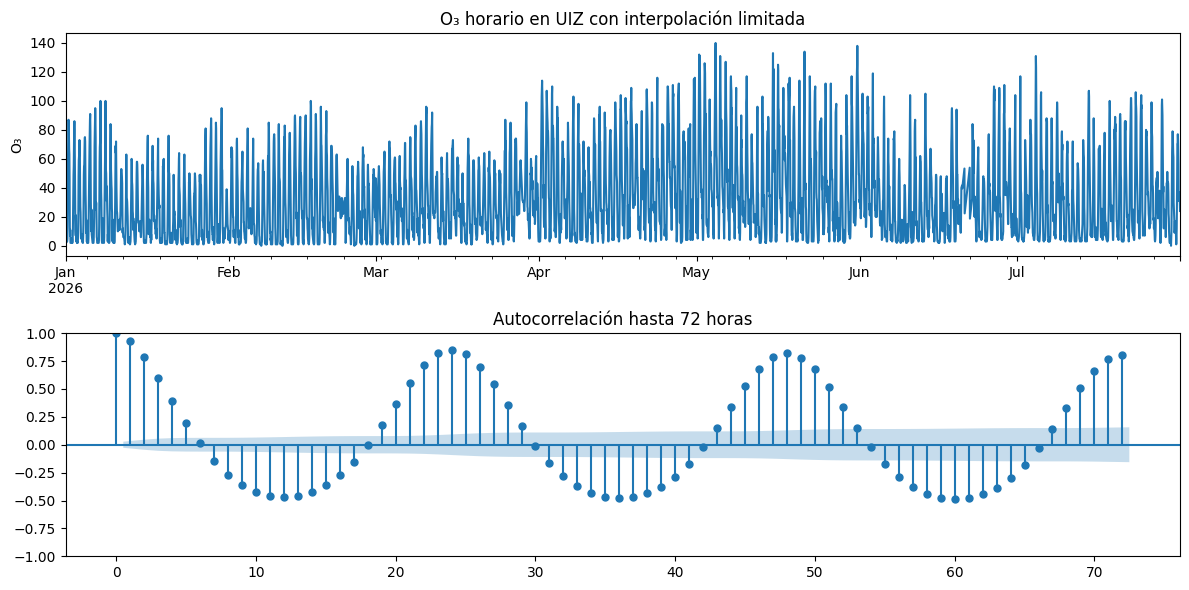

In [2]:
fig, ejes = plt.subplots(2, 1, figsize=(12, 6))
serie.plot(ax=ejes[0], title="O₃ horario en UIZ con interpolación limitada", ylabel="O₃")
plot_acf(serie, lags=72, ax=ejes[1], title="Autocorrelación hasta 72 horas")
fig.tight_layout()
plt.show()

por_hora = serie.groupby(serie.index.hour).transform("mean")
por_mes_hora = serie.groupby([serie.index.month, serie.index.hour]).transform("mean")
versiones = {
    "Original imputada": serie,
    "Sin media por hora": serie - por_hora,
    "Sin media por mes y hora": serie - por_mes_hora,
    "Diferencia de 24 h": serie.diff(24),
}

/tmp/ipykernel_574/3331637796.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  estad_adf, p_adf, *_ = adfuller(muestra, autolag="AIC")
/tmp/ipykernel_574/3331637796.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  estad_kpss, p_kpss, *_ = kpss(muestra, regression="c", nlags="auto")
/tmp/ipykernel_574/3331637796.py:4: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will s

,Horas válidas,ADF,p ADF,KPSS,p KPSS,Varianza,Ambas compatibles con estacionariedad
Original imputada,5088,-5.8059,4.52e-07,2.5393,0.01,837.36,False
Sin media por hora,5088,-5.7076,7.43e-07,2.7053,0.01,235.37,False
Sin media por mes y hora,5088,-8.1303,1.09e-12,0.0509,0.1,160.47,True
Diferencia de 24 h,5064,-16.1952,4.13e-29,0.0094,0.1,239.93,True


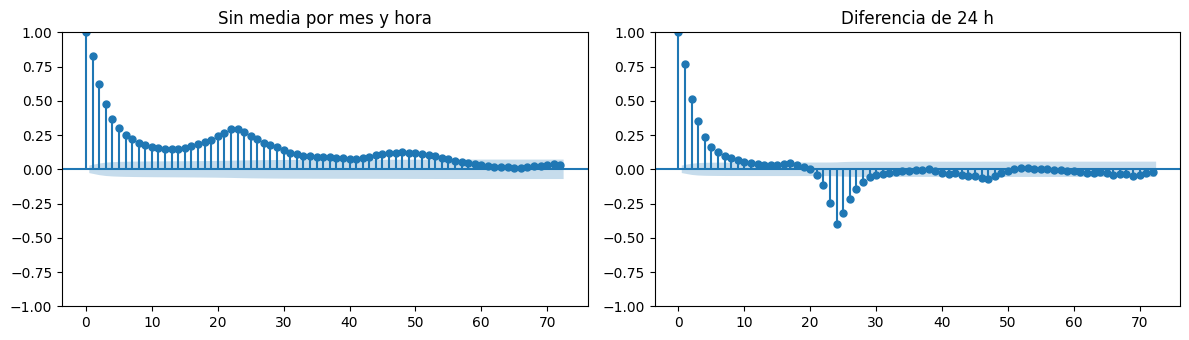

Cociente de varianzas (diferencia / media mes-hora): 1.4952


In [3]:
def diagnostico(valores):
    muestra = valores.dropna()
    estad_adf, p_adf, *_ = adfuller(muestra, autolag="AIC")
    estad_kpss, p_kpss, *_ = kpss(muestra, regression="c", nlags="auto")
    return {
        "Horas válidas": len(muestra),
        "ADF": estad_adf, "p ADF": p_adf,
        "KPSS": estad_kpss, "p KPSS": p_kpss,
        "Varianza": muestra.var(),
        "Ambas compatibles con estacionariedad": p_adf < .05 <= p_kpss,
    }

resumen = pd.DataFrame({nombre: diagnostico(datos) for nombre, datos in versiones.items()}).T
display(resumen.style.format({
    "Horas válidas": "{:d}", "ADF": "{:.4f}", "p ADF": "{:.3g}",
    "KPSS": "{:.4f}", "p KPSS": "{:.3g}", "Varianza": "{:.2f}",
}))
comparadas = ["Sin media por mes y hora", "Diferencia de 24 h"]
fig, ejes = plt.subplots(1, 2, figsize=(12, 3.5))
for eje, nombre in zip(ejes, comparadas):
    plot_acf(versiones[nombre].dropna(), lags=72, ax=eje, title=nombre)
fig.tight_layout()
plt.show()

base, alternativa = resumen.loc[comparadas, "Varianza"].astype(float)
print(f"Cociente de varianzas (diferencia / media mes-hora): {alternativa / base:.4f}")

## Resultados

Con un umbral del 5 %, un p pequeño en ADF aporta evidencia contra una raíz unitaria. Un p pequeño en KPSS aporta evidencia contra la estacionariedad alrededor de una media constante. En este ejercicio, restar la media por mes y hora y diferenciar a 24 horas permiten que las dos pruebas sean compatibles con estacionariedad. Tambien se puede ver qUE transformación deja menos dispersión y cómo cambia el patrón diario.